In [1]:
import pandas as pd

tx = pd.read_csv("../data/raw/train_transaction.csv")
idn = pd.read_csv("../data/raw/train_identity.csv")

print(tx.shape, idn.shape)
print(tx["isFraud"].value_counts(normalize=True))
print(tx.memory_usage(deep=True).sum() / 1e9, "GB")

(590540, 394) (144233, 41)
isFraud
0    0.96501
1    0.03499
Name: proportion, dtype: float64
1.878653337 GB


In [2]:
import numpy as np

def reduce_mem(df):
    for col in df.select_dtypes("float64").columns:
        df[col] = df[col].astype("float32")
    for col in df.select_dtypes("int64").columns:
        df[col] = pd.to_numeric(df[col], downcast="integer")
    return df

tx = reduce_mem(tx)
idn = reduce_mem(idn)
print(tx.memory_usage(deep=True).sum() / 1e9, "GB")

0.978079837 GB


In [4]:
df = tx.merge(idn, on="TransactionID", how="left").copy()
df["has_identity"] = df["id_01"].notna().astype(int)
print(df.shape)
print(df.groupby("has_identity")["isFraud"].mean())

(590540, 435)
has_identity
0    0.020939
1    0.078470
Name: isFraud, dtype: float64


In [5]:
del tx, idn
import gc; gc.collect()

169

86400 15811131
Days covered: 181


Matplotlib is building the font cache; this may take a moment.


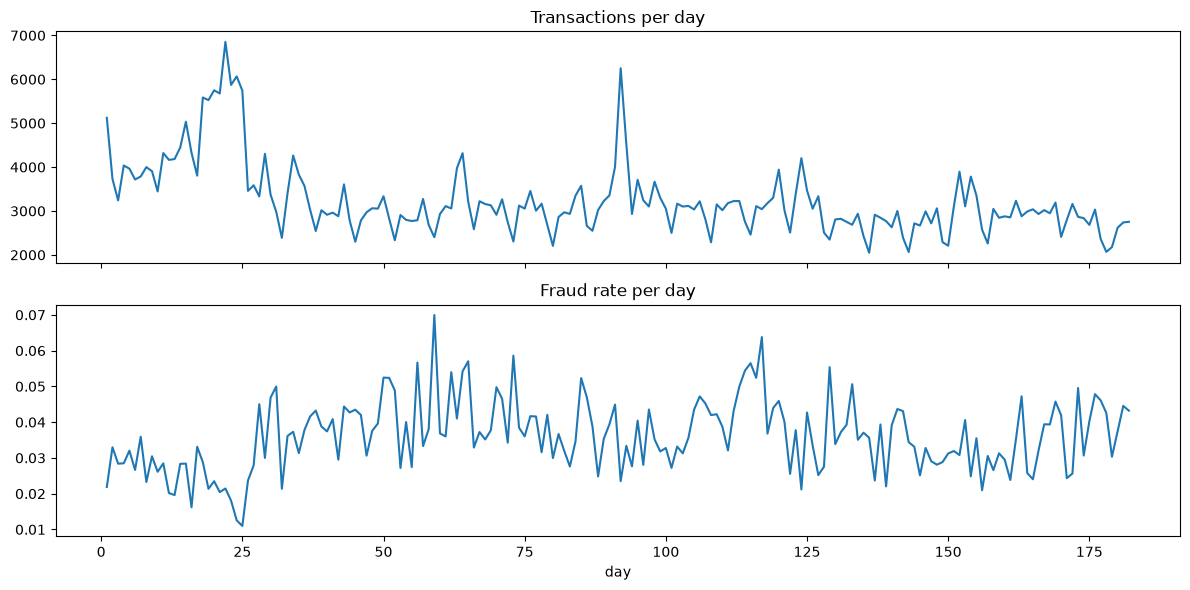

In [6]:
df["day"] = df["TransactionDT"] // 86400
print(df["TransactionDT"].min(), df["TransactionDT"].max())
print("Days covered:", df["day"].max() - df["day"].min())

import matplotlib.pyplot as plt
daily = df.groupby("day")["isFraud"].agg(["count", "mean"])
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
daily["count"].plot(ax=ax[0], title="Transactions per day")
daily["mean"].plot(ax=ax[1], title="Fraud rate per day")
plt.tight_layout(); plt.show()

In [7]:
missing = df.isna().mean().sort_values(ascending=False)
print((missing > 0.5).sum(), "columns are more than 50% empty")
print(missing.head(15))

214 columns are more than 50% empty
id_24    0.991962
id_25    0.991310
id_08    0.991271
id_07    0.991271
id_21    0.991264
id_26    0.991257
id_27    0.991247
id_23    0.991247
id_22    0.991247
dist2    0.936284
D7       0.934099
id_18    0.923607
D13      0.895093
D14      0.894695
D12      0.890410
dtype: float64


In [8]:
print(df.groupby("isFraud")["TransactionAmt"].describe())
print(df.groupby("ProductCD")["isFraud"].agg(["count", "mean"]).sort_values("mean", ascending=False))

            count        mean         std    min        25%   50%    75%  \
isFraud                                                                    
0        569877.0  134.511658  239.395081  0.251  43.970001  68.5  120.0   
1         20663.0  149.244766  232.212158  0.292  35.043999  75.0  161.0   

                  max  
isFraud                
0        31937.390625  
1         5191.000000  
            count      mean
ProductCD                  
C           68519  0.116873
S           11628  0.058996
H           33024  0.047662
R           37699  0.037826
W          439670  0.020399


In [9]:
train_end = 140   # days 1-140 for training
gap = 7           # skip a week
valid_start = train_end + gap

train = df[df["day"] <= train_end]
valid = df[df["day"] >= valid_start]

print("Train:", train.shape, "days", train["day"].min(), "-", train["day"].max())
print("Valid:", valid.shape, "days", valid["day"].min(), "-", valid["day"].max())
print("Train fraud rate:", round(train["isFraud"].mean(), 4))
print("Valid fraud rate:", round(valid["isFraud"].mean(), 4))

Train: (472006, 436) days 1 - 140
Valid: (102703, 436) days 147 - 182
Train fraud rate: 0.0351
Valid fraud rate: 0.0342


In [10]:
train.to_parquet("../data/processed/train.parquet")
valid.to_parquet("../data/processed/valid.parquet")

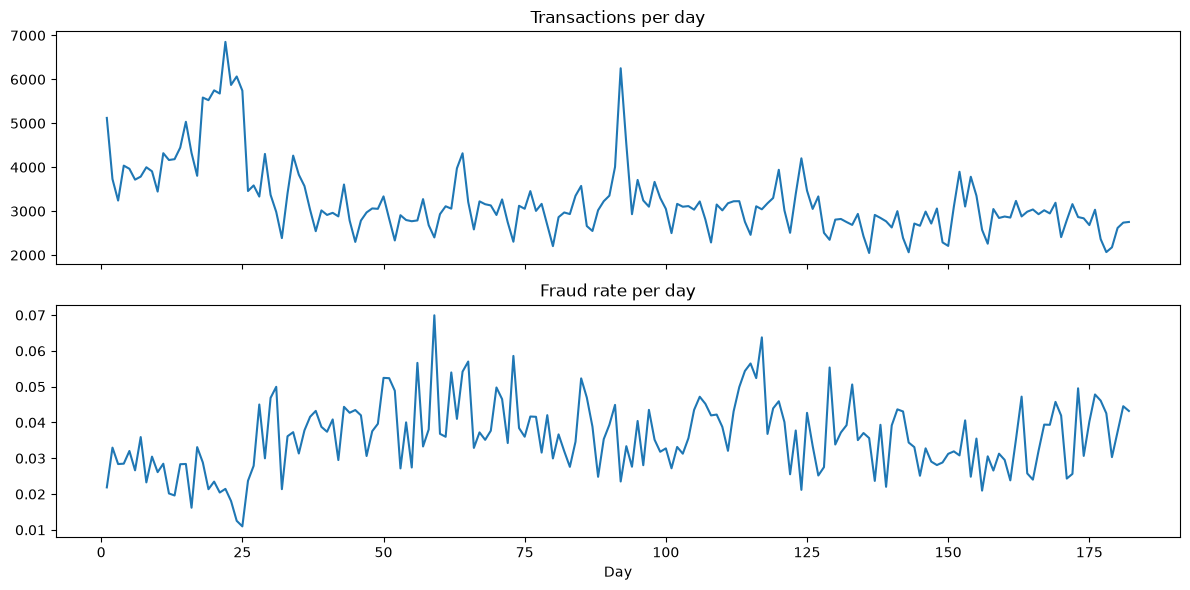

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("../figures", exist_ok=True)

tx = pd.read_csv("../data/raw/train_transaction.csv", usecols=["TransactionDT", "isFraud"])
tx["day"] = tx["TransactionDT"] // 86400

daily = tx.groupby("day")["isFraud"].agg(["count", "mean"])

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
daily["count"].plot(ax=ax[0], title="Transactions per day")
daily["mean"].plot(ax=ax[1], title="Fraud rate per day")
ax[1].set_xlabel("Day")
plt.tight_layout()
plt.savefig("../figures/fraud_over_time.png", dpi=150, bbox_inches="tight")
plt.show()